In [2]:
#Әр жаңа файл ашылғанда ядро жаңа болады, сондықтан айнымалылар жоқ. Әр файлдың басына мына ұяшықты қойыңыз
from pathlib import Path

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
RAW_DIR = PROJECT_ROOT / "data" / "raw"

print("Жоба қалтасы :", PROJECT_ROOT, "| бар:", PROJECT_ROOT.exists())
print("RAW қалтасы  :", RAW_DIR, "| бар:", RAW_DIR.exists())

Жоба қалтасы : D:\road_damage_yolo | бар: True
RAW қалтасы  : D:\road_damage_yolo\data\raw | бар: True


Ұяшық 2.1. Жолдарды орнату және архивті тексеру

In [1]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
RAW_DIR = PROJECT_ROOT / "data" / "raw"

zips = sorted(RAW_DIR.glob("*.zip"))
if not zips:
    print("❌ data\\raw қалтасында .zip файлы жоқ. Алдымен архивті жүктеп, осы қалтаға салыңыз.")
for z in zips:
    print(f"✅ {z.name}  |  {z.stat().st_size/1e6:.1f} МБ")

✅ RDD2020 Mendeley.zip  |  1848.1 МБ


Ұяшық 2.2. Архивтің ішін ашпай қарау

In [2]:
import zipfile
from collections import Counter

ZIP_PATH = zips[0]   # бірнеше болса, қажеттісін таңдаңыз

with zipfile.ZipFile(ZIP_PATH) as zf:
    infos = zf.infolist()
    print("Жазба саны:", len(infos))
    print("Ашылған көлем: %.2f ГБ" % (sum(i.file_size for i in infos)/1e9))
    print("\nАлғашқы 30 жазба:")
    for i in infos[:30]:
        print(f"{i.file_size/1e6:10.1f} МБ  {i.filename}")
    ext = Counter(Path(i.filename).suffix.lower() for i in infos if not i.is_dir())
    print("\nКеңейтімдер:", dict(ext))

Жазба саны: 4
Ашылған көлем: 1.85 ГБ

Алғашқы 30 жазба:
    1472.6 МБ  train.tar.gz
     188.7 МБ  test2.tar.gz
     186.5 МБ  test1.tar.gz
       1.7 МБ  FileStructure.txt

Кеңейтімдер: {'.gz': 3, '.txt': 1}


Ұяшық 2.3. FileStructure.txt оқу

In [4]:
import zipfile
from pathlib import Path

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
ZIP_PATH = RAW_DIR / "RDD2020 Mendeley.zip"

with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extract("FileStructure.txt", RAW_DIR)

lines = (RAW_DIR / "FileStructure.txt").read_text(encoding="utf-8", errors="replace").splitlines()
print("Жол саны:", len(lines))
print("\n".join(lines[:60]))

Жол саны: 47435
Folder PATH listing
Volume serial number is 6823-03D7
C:.
|   FileStructure.txt
|   
+---test1
|   +---Czech
|   |   +---annotations
|   |   |   \---xmls
|   |   \---images
|   |           Czech_000004.jpg
|   |           Czech_000016.jpg
|   |           Czech_000019.jpg
|   |           Czech_000026.jpg
|   |           Czech_000035.jpg
|   |           Czech_000042.jpg
|   |           Czech_000051.jpg
|   |           Czech_000053.jpg
|   |           Czech_000059.jpg
|   |           Czech_000073.jpg
|   |           Czech_000082.jpg
|   |           Czech_000088.jpg
|   |           Czech_000094.jpg
|   |           Czech_000096.jpg
|   |           Czech_000099.jpg
|   |           Czech_000114.jpg
|   |           Czech_000116.jpg
|   |           Czech_000130.jpg
|   |           Czech_000138.jpg
|   |           Czech_000166.jpg
|   |           Czech_000169.jpg
|   |           Czech_000172.jpg
|   |           Czech_000198.jpg
|   |           Czech_000210.jpg
|   |           Cze

Ұяшық 2.4. train.tar.gz архивін шығару

In [5]:
with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extract("train.tar.gz", RAW_DIR)

tar_path = RAW_DIR / "train.tar.gz"
print("✅", tar_path.name, "|", f"{tar_path.stat().st_size/1e6:.1f} МБ")

✅ train.tar.gz | 1472.6 МБ


Ұяшық 2.5. train.tar.gz ішін ашпай қарау

In [6]:
import tarfile
from collections import Counter

cnt = Counter()
first = []

with tarfile.open(tar_path, "r:gz") as tf:
    for m in tf:
        if not m.isfile():
            continue
        parts = m.name.split("/")
        folder = "/".join(parts[:-1][:3])
        ext = Path(m.name).suffix.lower()
        cnt[(folder, ext)] += 1
        if len(first) < 15:
            first.append(m.name)

print("Алғашқы 15 файл:")
for n in first:
    print("  ", n)
print()
for (folder, ext), n in sorted(cnt.items()):
    print(f"{folder:50s} {ext:6s} {n}")

Алғашқы 15 файл:
   train/Czech/images/Czech_000982.jpg
   train/Czech/images/Czech_003323.jpg
   train/Czech/images/Czech_001359.jpg
   train/Czech/images/Czech_002850.jpg
   train/Czech/images/Czech_002553.jpg
   train/Czech/images/Czech_002404.jpg
   train/Czech/images/Czech_001042.jpg
   train/Czech/images/Czech_000031.jpg
   train/Czech/images/Czech_001918.jpg
   train/Czech/images/Czech_003478.jpg
   train/Czech/images/Czech_003009.jpg
   train/Czech/images/Czech_000763.jpg
   train/Czech/images/Czech_003390.jpg
   train/Czech/images/Czech_001406.jpg
   train/Czech/images/Czech_001730.jpg

train                                              .pbtxt 1
train/Czech/annotations                            .xml   2829
train/Czech/images                                 .jpg   2829
train/India/annotations                            .xml   7706
train/India/images                                 .jpg   7706
train/Japan/annotations                            .xml   10506
train/Japan/images   

Ұяшық 2.6. train архивін ашу

In [8]:
import tarfile
from pathlib import Path

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_TAR = RAW_DIR / "train.tar.gz"
EXTRACT_DIR = RAW_DIR / "rdd2020"
EXTRACT_DIR.mkdir(exist_ok=True)

with tarfile.open(TRAIN_TAR, "r:gz") as tf:
    tf.extractall(EXTRACT_DIR, filter="data")

print("✅ Ашылды:", EXTRACT_DIR)

✅ Ашылды: D:\road_damage_yolo\data\raw\rdd2020


Ұяшық 2.7. Класс картасын (.pbtxt) оқу

In [9]:
TRAIN_DIR = EXTRACT_DIR / "train"
pb = list(TRAIN_DIR.glob("*.pbtxt"))
print("Табылған .pbtxt:", [p.name for p in pb])
if pb:
    print(pb[0].read_text(encoding="utf-8"))

Табылған .pbtxt: ['label_map.pbtxt']
item {
  id: 1
  name: 'D00'
}

item {
  id: 2
  name: 'D10'
}

item {
  id: 3
  name: 'D20'
}

item {
  id: 4
  name: 'D40'
}



Ұяшық 2.8. Суреттер мен XML-ді сәйкестендіру және кластарды санау

In [10]:
import xml.etree.ElementTree as ET
from collections import Counter

all_classes = Counter()

for country in ["Czech", "India", "Japan"]:
    img_dir = TRAIN_DIR / country / "images"
    xml_dir = TRAIN_DIR / country / "annotations"

    imgs = {p.stem for p in img_dir.glob("*.jpg")}
    xmls = {p.stem: p for p in xml_dir.rglob("*.xml")}

    only_img = sorted(imgs - set(xmls))
    only_xml = sorted(set(xmls) - imgs)

    cls, sizes = Counter(), Counter()
    empty = bad = n_boxes = 0

    for stem, p in xmls.items():
        try:
            root = ET.parse(p).getroot()
        except ET.ParseError:
            bad += 1
            continue
        objs = root.findall("object")
        if not objs:
            empty += 1
        for o in objs:
            cls[(o.findtext("name") or "").strip()] += 1
            n_boxes += 1
        sizes[(root.findtext("size/width"), root.findtext("size/height"))] += 1

    all_classes.update(cls)
    print(f"\n===== {country} =====")
    print("Сурет:", len(imgs), "| XML:", len(xmls))
    print("Тек суреті бар (XML жоқ):", len(only_img), only_img[:3])
    print("Тек XML бар (суреті жоқ):", len(only_xml), only_xml[:3])
    print("Бұзылған XML:", bad)
    print("Ақаусыз сурет (object жоқ):", empty)
    print("Қорап саны:", n_boxes)
    print("Кластар:", dict(cls))
    print("Ең жиі өлшемдер (w, h):", sizes.most_common(3))

print("\n===== БАРЛЫҒЫ, кластар =====")
print(dict(all_classes))


===== Czech =====
Сурет: 2829 | XML: 2829
Тек суреті бар (XML жоқ): 0 []
Тек XML бар (суреті жоқ): 0 []
Бұзылған XML: 0
Ақаусыз сурет (object жоқ): 1757
Қорап саны: 1745
Кластар: {'D00': 988, 'D40': 197, 'D10': 399, 'D20': 161}
Ең жиі өлшемдер (w, h): [(('600', '600'), 2829)]

===== India =====
Сурет: 7706 | XML: 7706
Тек суреті бар (XML жоқ): 0 []
Тек XML бар (суреті жоқ): 0 []
Бұзылған XML: 0
Ақаусыз сурет (object жоқ): 3921
Қорап саны: 8203
Кластар: {'D40': 3187, 'D44': 1062, 'D00': 1555, 'D20': 2021, 'D01': 179, 'D11': 45, 'D10': 68, 'D50': 28, 'D43': 57, 'D0w0': 1}
Ең жиі өлшемдер (w, h): [(('720', '720'), 7706)]

===== Japan =====
Сурет: 10506 | XML: 10506
Тек суреті бар (XML жоқ): 0 []
Тек XML бар (суреті жоқ): 0 []
Бұзылған XML: 0
Ақаусыз сурет (object жоқ): 794
Қорап саны: 24754
Кластар: {'D20': 6199, 'D40': 2243, 'D10': 3979, 'D00': 4049, 'D44': 3995, 'D43': 736, 'D50': 3553}
Ең жиі өлшемдер (w, h): [(('600', '600'), 10187), (('1024', '1024'), 147), (('540', '540'), 124)]

=

Ұяшық 2.9. Тест архивтерінде аннотация бар ма

In [12]:
import zipfile, tarfile
from collections import Counter
from pathlib import Path

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
ZIP_PATH = RAW_DIR / "RDD2020 Mendeley.zip"

for name in ["test1.tar.gz", "test2.tar.gz"]:
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extract(name, RAW_DIR)
    cnt = Counter()
    with tarfile.open(RAW_DIR / name, "r:gz") as tf:
        for m in tf:
            if m.isfile():
                parts = m.name.split("/")
                cnt[("/".join(parts[:-1][:3]), Path(m.name).suffix.lower())] += 1
    print("\n=====", name)
    for (folder, ext), n in sorted(cnt.items()):
        print(f"{folder:45s} {ext:6s} {n}")


===== test1.tar.gz
test1/Czech/images                            .jpg   349
test1/India/images                            .jpg   969
test1/Japan/images                            .jpg   1313

===== test2.tar.gz
test2/Czech/images                            .jpg   360
test2/India/images                            .jpg   990
test2/Japan/images                            .jpg   1314


Ұяшық 2.10. 4 класқа сүзгі әсері және таралу графигі

         images  no_objects  only_other_classes  with_target
country                                                     
Czech      2829        1757                   0         1072
India      7706        3921                 562         3223
Japan     10506         794                1812         7900

Жалпы:
 images                21041
no_objects             6472
only_other_classes     2374
with_target           12195
dtype: int64


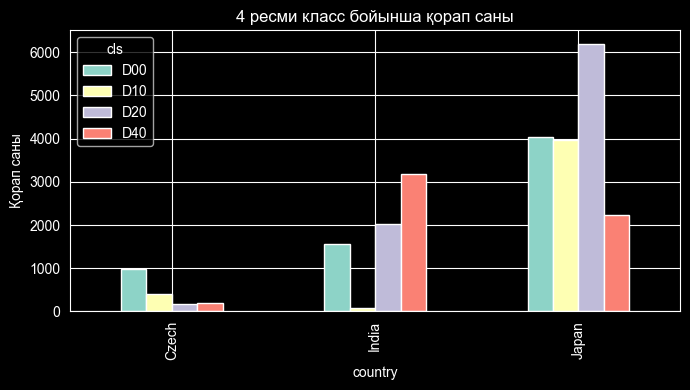

In [13]:
import xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt

TRAIN_DIR = RAW_DIR / "rdd2020" / "train"
TARGET = ["D00", "D10", "D20", "D40"]
COUNTRIES = ["Czech", "India", "Japan"]

img_rows, box_rows = [], []
for country in COUNTRIES:
    for p in (TRAIN_DIR / country / "annotations").rglob("*.xml"):
        root = ET.parse(p).getroot()
        names = [(o.findtext("name") or "").strip() for o in root.findall("object")]
        img_rows.append((country, p.stem, len(names), sum(n in TARGET for n in names)))
        box_rows += [(country, n) for n in names]

img = pd.DataFrame(img_rows, columns=["country", "stem", "n_all", "n_target"])
box = pd.DataFrame(box_rows, columns=["country", "cls"])

img["only_other"] = (img.n_all > 0) & (img.n_target == 0)
summary = img.groupby("country").agg(
    images=("stem", "count"),
    no_objects=("n_all", lambda s: int((s == 0).sum())),
    only_other_classes=("only_other", "sum"),
    with_target=("n_target", lambda s: int((s > 0).sum())),
)
print(summary)
print("\nЖалпы:\n", summary.sum())

ct = box[box.cls.isin(TARGET)].groupby(["country", "cls"]).size().unstack(fill_value=0)[TARGET]
ax = ct.plot(kind="bar", figsize=(7, 4))
ax.set_title("4 ресми класс бойынша қорап саны")
ax.set_ylabel("Қорап саны")
plt.tight_layout()
(PROJECT_ROOT / "results" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(PROJECT_ROOT / "results" / "figures" / "class_distribution_target.png", dpi=150)
plt.show()

Ұяшық 2.11. Белгілері салынған суреттер

Табылған XML саны: 21041
Мысал жол: D:\road_damage_yolo\data\raw\rdd2020\train\Czech\annotations\xmls\Czech_000000.xml


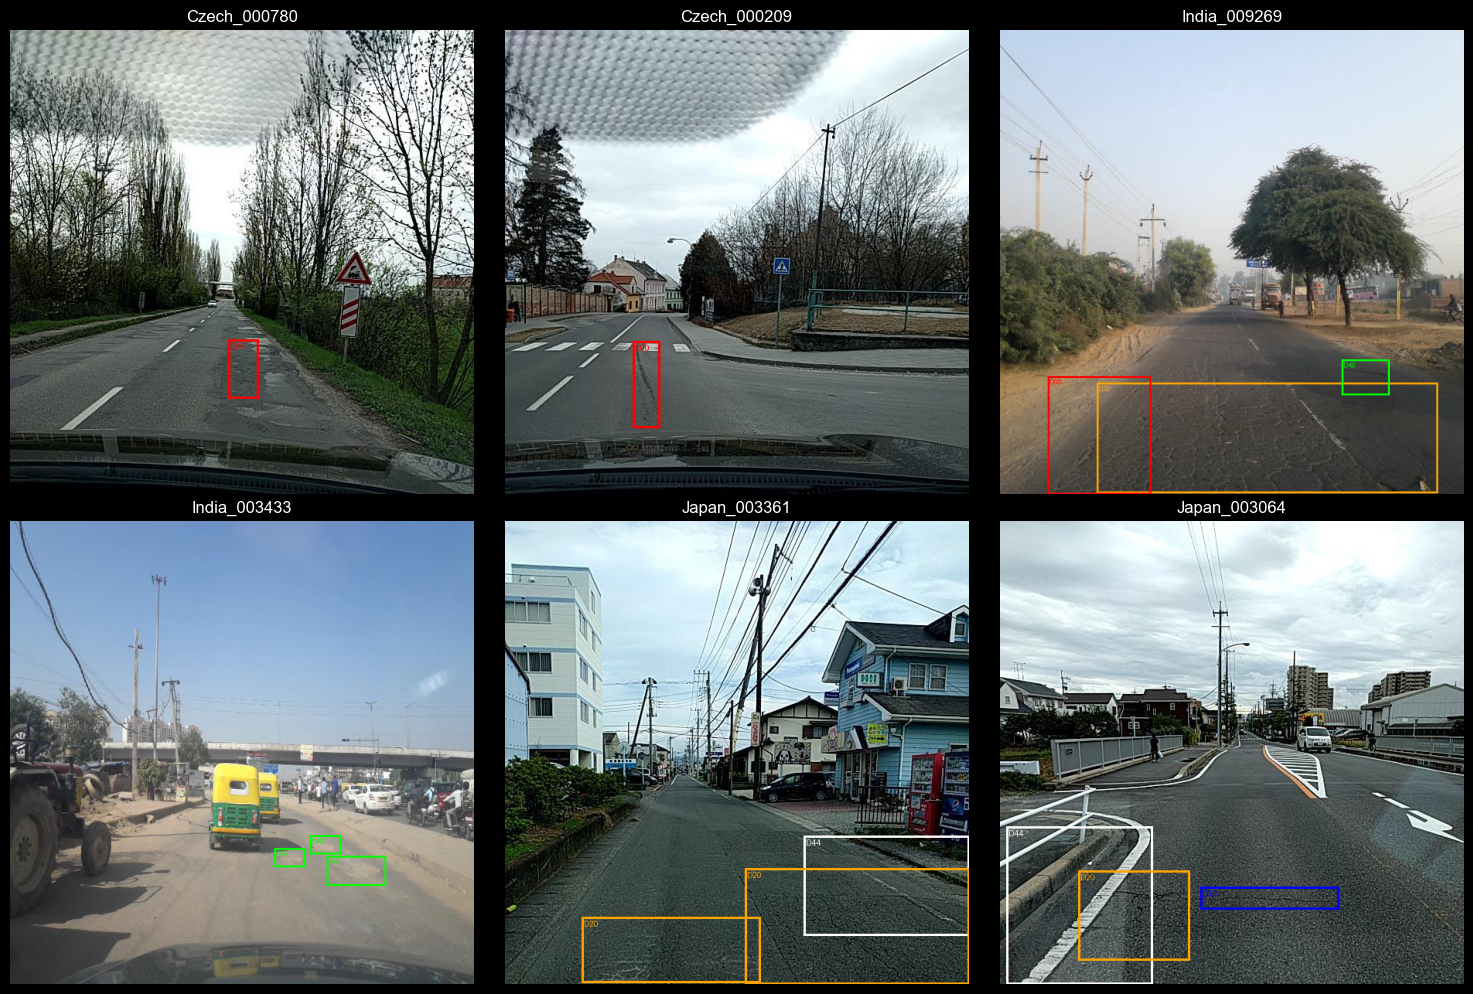

In [15]:
import random
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# 1) XML файлдарының нақты жолдарын жинау (ішкі қалталармен)
xml_index = {}
for country in COUNTRIES:
    for p in (TRAIN_DIR / country / "annotations").rglob("*.xml"):
        xml_index[p.stem] = p

print("Табылған XML саны:", len(xml_index))
print("Мысал жол:", next(iter(xml_index.values())))

# 2) Қораптарды салу
random.seed(42)
colors = {"D00": "red", "D10": "blue", "D20": "orange", "D40": "lime"}

samples = []
for country in COUNTRIES:
    cand = img[(img.country == country) & (img.n_target > 0)]["stem"].tolist()
    samples += [(country, s) for s in random.sample(cand, 2)]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (country, stem) in zip(axes.ravel(), samples):
    im = Image.open(TRAIN_DIR / country / "images" / f"{stem}.jpg").convert("RGB")
    d = ImageDraw.Draw(im)
    root = ET.parse(xml_index[stem]).getroot()
    for o in root.findall("object"):
        n = (o.findtext("name") or "").strip()
        bb = o.find("bndbox")
        x1, y1, x2, y2 = [float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
        c = colors.get(n, "white")
        d.rectangle([x1, y1, x2, y2], outline=c, width=3)
        d.text((x1 + 3, y1 + 3), n, fill=c)
    ax.imshow(im)
    ax.set_title(stem)
    ax.axis("off")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "sample_annotations.png", dpi=150)
plt.show()

Ұяшық 2.12. Аралас суреттер және таңдалған саясаттың нәтижесі

In [16]:
img["mixed"] = (img.n_target > 0) & (img.n_all > img.n_target)
mixed = img.groupby("country")["mixed"].agg(mixed_images="sum", share="mean")
print("Ресми және ресми емес класс қатар болатын суреттер:")
print(mixed)

keep = img[~img.only_other]
print("\nА нұсқасы: 'тек басқа класс' суреттерін алып тастағанда:")
print(keep.groupby("country").agg(
    images=("stem", "count"),
    with_target=("n_target", lambda s: int((s > 0).sum())),
    negatives=("n_all", lambda s: int((s == 0).sum())),
))

Ресми және ресми емес класс қатар болатын суреттер:
         mixed_images     share
country                        
Czech               0  0.000000
India             494  0.064106
Japan            3767  0.358557

А нұсқасы: 'тек басқа класс' суреттерін алып тастағанда:
         images  with_target  negatives
country                                
Czech      2829         1072       1757
India      7144         3223       3921
Japan      8694         7900        794


Ұяшық 2.13. Ресми емес кластардың нақты көрінісі

D43 қорап саны: 793
D44 қорап саны: 5057
D50 қорап саны: 3581


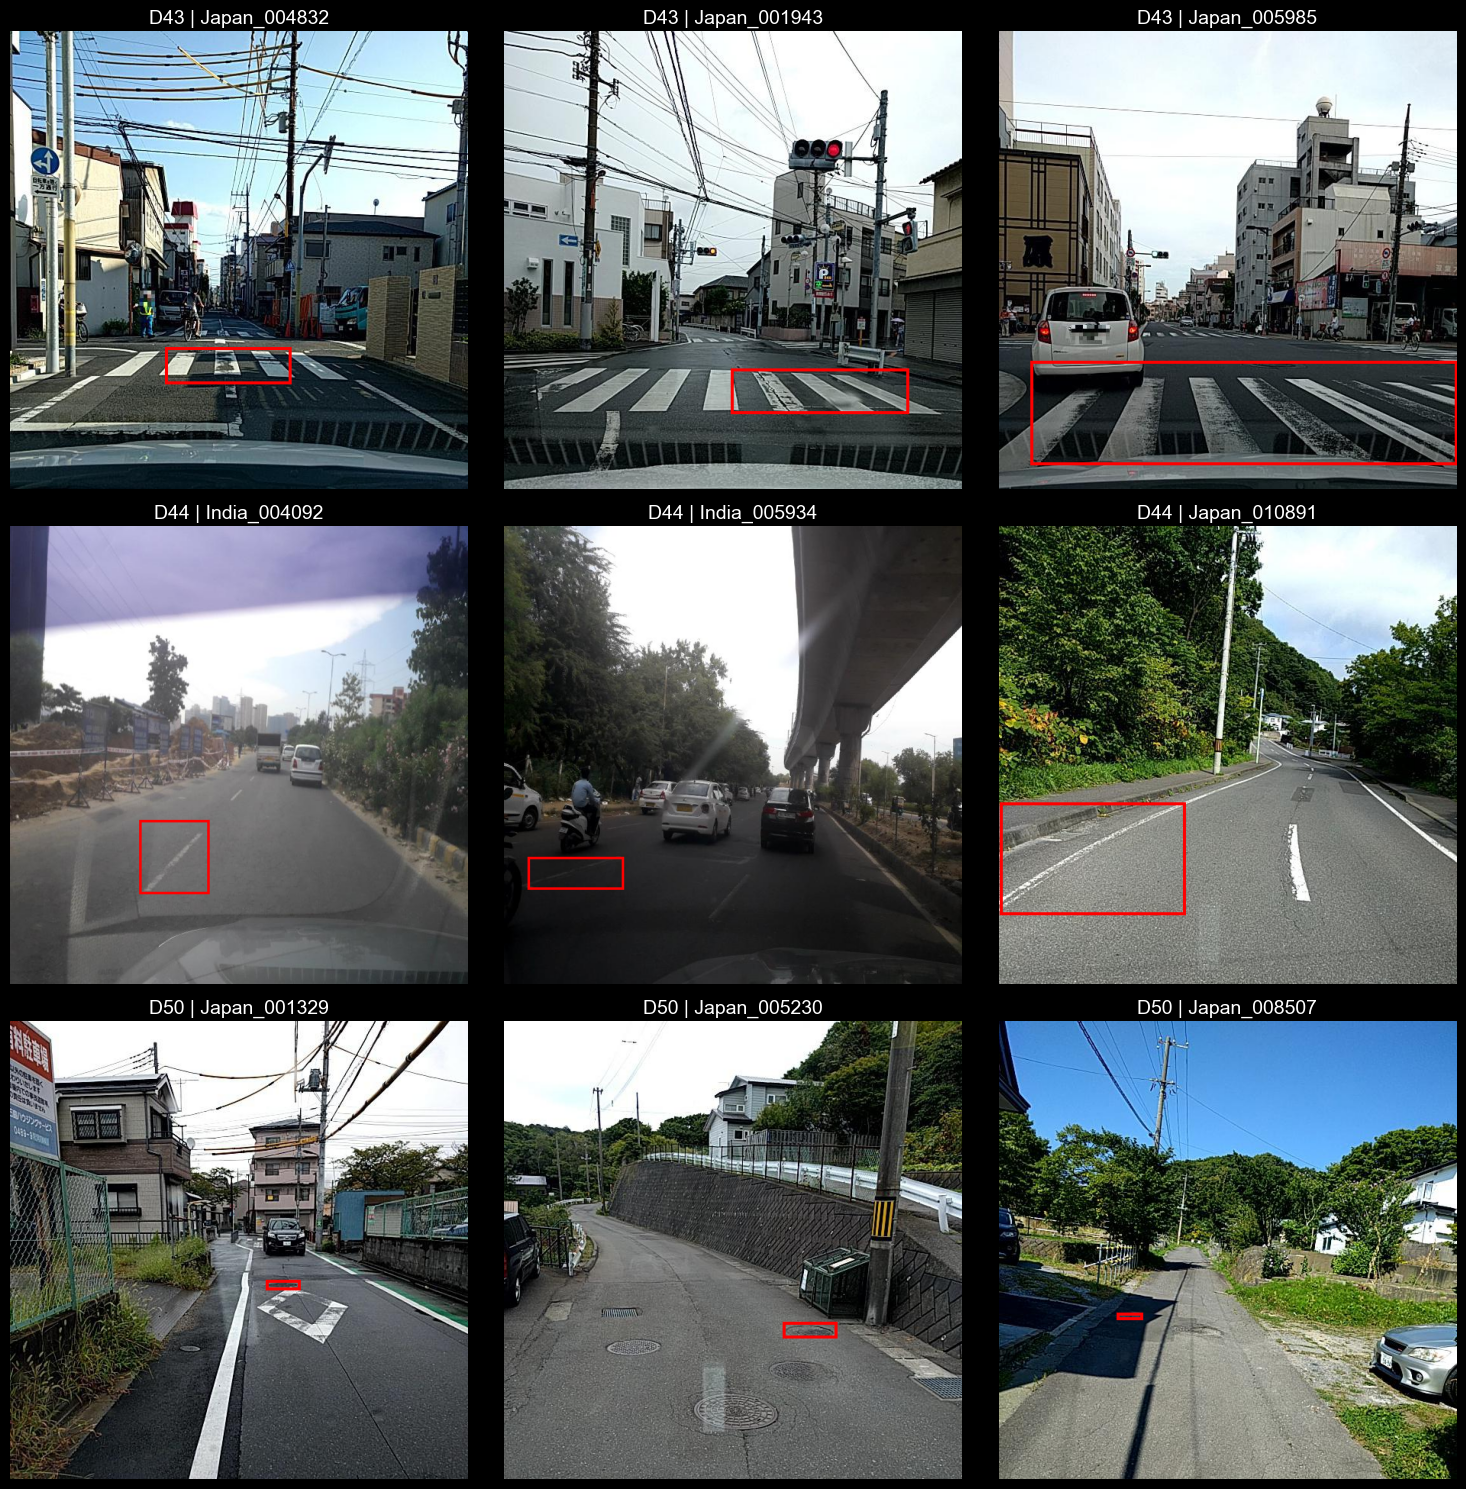

In [17]:
import random
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

random.seed(7)
OTHER = ["D43", "D44", "D50"]
found = {c: [] for c in OTHER}

for stem, p in xml_index.items():
    country = stem.split("_")[0]
    root = ET.parse(p).getroot()
    for o in root.findall("object"):
        n = (o.findtext("name") or "").strip()
        if n in found:
            bb = o.find("bndbox")
            box = [float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
            found[n].append((country, stem, box))

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for r, cls in enumerate(OTHER):
    print(cls, "қорап саны:", len(found[cls]))
    for c, (country, stem, box) in enumerate(random.sample(found[cls], 3)):
        im = Image.open(TRAIN_DIR / country / "images" / f"{stem}.jpg").convert("RGB")
        ImageDraw.Draw(im).rectangle(box, outline="red", width=4)
        axes[r][c].imshow(im)
        axes[r][c].set_title(f"{cls} | {stem}", fontsize=14)
        axes[r][c].axis("off")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "other_classes_samples.png", dpi=120)
plt.show()